We did an end-to-end case for the past two weeks to give you a broad overview of what a data science project could look like using the CRISP-DM framework. From now on we'll take a slower, more methodological approach to ensure you are capable of taking on such a project yourself.

<img src="images\Logo_UCLL_ENG_RGB.png" style="background-color:white;" />

# Data Analytics & Machine learning

Lecturers: Aimée Lynn Backiel, Lies Bollens, Fien Van de Woestijne

Academic year 2026-2027

## Lab 6 Part 2: End-to-end exercise + classification

### Lecture outline

1. One large exercise covering all we have done so far in this course applied to classification.

### Recap of last lecture(s)

#### Lab 1

1. We ensured we had a valid Python installation.
2. We learnt what a virtual environment is:
   * Isolated Python executable and packages.
   * We created a virtual environment.
3. Absolute path vs relative path recap.
4. Recap of data structures in Python

#### Lab 2
1. Installed Pandas
2. Learnt how to read data
3. Learnt how to calculate mean, mode, median etc.
4. Basic exploration of the 4 variables

#### Lab 3
1. Wrapped up computing summary statistics (mean, median, mode, ...)
2. Learnt how to deal with outliers 
3. Focused on exploration of dat

#### Lab 4
1. Univariate data visualization using Matplotlib
   1. Figures and axes
   2. Histograms
   3. Box plots
   4. Bar charts
2. Multivariate data visualization using Seaborn
   1. Scatter plots
   2. Small multiples
   3. Color coding

#### Lab 5
1. Intro to machine learning using scikit-learn
   1. Preprocessing
      1. One Hot encoding
      2. Scaling
      3. Outliers
   2. Regression

#### Lab 6
1. Preprocessing with scikit-learn
   1. ColumnTransformer: Apply a transformation to specific columns.
   2. Pipeline: Do several transformations after each other
2. Evaluation:
   1. Why the mean of the error is a bad idea
   2. Mean absolute error
   3. Mean squared error

### Lab 7
1. Feature engineering
   1. Binning
   2. Interactions
   3. Custom features
2. Rounding up model evaluation
   1. Cross validation
   2. Hyper parameter tuning

#### Our next case: Hotel booking dataset

source: https://www.sciencedirect.com/science/article/pii/S2352340918315191

*This data article describes two datasets with hotel demand data. One of the hotels (H1) is a resort hotel and the other is a city hotel (H2). Both datasets share the same structure, with 31 variables describing the 40,060 observations of H1 and 79,330 observations of H2. Each observation represents a hotel booking. Both datasets comprehend bookings due to arrive between the 1st of July of 2015 and the 31st of August 2017, including bookings that effectively arrived and bookings that were canceled. Both hotels are located in Portugal: H1 at the resort region of Algarve and H2 at the city of Lisbon.*

The goal is to help the two hotels maximize their revenue.



|variable                       |class     |description |
|:------------------------------|:---------|:-----------|
|hotel                          |character | Hotel (H1 = Resort Hotel or H2 = City Hotel) |
|is_canceled                    |double    | Value indicating if the booking was canceled (1) or not (0) |
|lead_time                      |double    | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date |
|arrival_date_year              |double    | Year of arrival date|
|arrival_date_month             |character | Month of arrival date|
|arrival_date_week_number       |double    | Week number of year for arrival date|
|arrival_date_day_of_month      |double    | Day of arrival date|
|stays_in_weekend_nights        |double    | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel |
|stays_in_week_nights           |double    |  Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel|
|adults                         |double    | Number of adults|
|children                       |double    | Number of children|
|babies                         |double    |Number of babies |
|meal                           |character | Type of meal booked. Categories are presented in standard hospitality meal packages: <br> Undefined/SC – no meal package;<br>BB – Bed & Breakfast; <br> HB – Half board (breakfast and one other meal – usually dinner); <br> FB – Full board (breakfast, lunch and dinner) |
|country                        |character | Country of origin. Categories are represented in the ISO 3155–3:2013 format |
|market_segment                 |character | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|distribution_channel           |character | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|is_repeated_guest              |double    | Value indicating if the booking name was from a repeated guest (1) or not (0) |
|previous_cancellations         |double    | Number of previous bookings that were cancelled by the customer prior to the current booking |
|previous_bookings_not_canceled |double    | Number of previous bookings not cancelled by the customer prior to the current booking |
|reserved_room_type             |character | Code of room type reserved. Code is presented instead of designation for anonymity reasons |
|assigned_room_type             |character | Code for the type of room assigned to the booking. Sometimes the assigned room type differs from the reserved room type due to hotel operation reasons (e.g. overbooking) or by customer request. Code is presented instead of designation for anonymity reasons |
|booking_changes                |double    | Number of changes/amendments made to the booking from the moment the booking was entered on the PMS until the moment of check-in or cancellation|
|deposit_type                   |character | Indication on if the customer made a deposit to guarantee the booking. This variable can assume three categories:<br>No Deposit – no deposit was made;<br>Non Refund – a deposit was made in the value of the total stay cost;<br>Refundable – a deposit was made with a value under the total cost of stay. |
|agent                          |character | ID of the travel agency that made the booking |
|company                        |character | ID of the company/entity that made the booking or responsible for paying the booking. ID is presented instead of designation for anonymity reasons |
|days_in_waiting_list           |double    | Number of days the booking was in the waiting list before it was confirmed to the customer |
|customer_type                  |character | Type of booking, assuming one of four categories:<br>Contract - when the booking has an allotment or other type of contract associated to it;<br>Group – when the booking is associated to a group;<br>Transient – when the booking is not part of a group or contract, and is not associated to other transient booking;<br>Transient-party – when the booking is transient, but is associated to at least other transient booking|
|adr                            |double    | Average Daily Rate as defined by dividing the sum of all lodging transactions by the total number of staying nights |
|required_car_parking_spaces    |double    | Number of car parking spaces required by the customer |
|total_of_special_requests      |double    | Number of special requests made by the customer (e.g. twin bed or high floor)|
|reservation_status             |character | Reservation last status, assuming one of three categories:<br>Canceled – booking was canceled by the customer;<br>Check-Out – customer has checked in but already departed;<br>No-Show – customer did not check-in and did inform the hotel of the reason why |
|reservation_status_date        |double    | Date at which the last status was set. This variable can be used in conjunction with the ReservationStatus to understand when was the booking canceled or when did the customer checked-out of the hotel|





In [1]:
import pandas as pd

In [2]:
h1 = pd.read_csv("data/H1.csv")
h1.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,...,No Deposit,NULL,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,0,13,2015,July,27,1,0,1,1,0,...,No Deposit,304,NULL,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,0,14,2015,July,27,1,0,2,2,0,...,No Deposit,240,NULL,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
h2 = pd.read_csv("data/H2.csv")
h2.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


#### ❓ The first thing we need to decide is what we want to do with this dataset. We have many different variables and thus things we can do. What would you do with this dataset?

My Answer: The main business goal is to help the resort hotel (H1) and city hotel (H2) maximize their revenue. The primary data science task is binary classification: predicting whether a booking will be canceled (IsCanceled = 1) or not (0) using booking details such as lead time, deposit type, market segment, stay duration, and special requests. Accurately predicting cancellations allows the hotels to optimize overbooking policies, adjust pricing, and manage room inventory proactively. (Secondary analyses could include regression on ADR to predict daily rates or clustering to segment customer profiles.)

The first goal, finding out who cancels, is **predicting a categorical value**. `isCanceled` is a number but in our dataset it should be regarded as a discrete category. This is called **classification**. When doing classification we will need slightly different machine learning models but most importantly, we will need different evaluation metrics. The full details are discussed in the theory sessions.

We still start of by doing exploring the dataset using Pandas exclusively and move on to some plots later on. The choice of which tool to use is yours.

In [4]:
h1["hotel"] = "Resort hotel"
h2["hotel"] = "City hotel"
hotel_df = pd.concat([h1, h2], ignore_index=True)

In [5]:
hotel_df

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,hotel
0,0,342,2015,July,27,1,0,0,2,0.0,...,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01,Resort hotel
1,0,737,2015,July,27,1,0,0,2,0.0,...,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01,Resort hotel
2,0,7,2015,July,27,1,0,1,1,0.0,...,NULL,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02,Resort hotel
3,0,13,2015,July,27,1,0,1,1,0.0,...,304,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02,Resort hotel
4,0,14,2015,July,27,1,0,2,2,0.0,...,240,NULL,0,Transient,98.00,0,1,Check-Out,2015-07-03,Resort hotel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,0,23,2017,August,35,30,2,5,2,0.0,...,394,NULL,0,Transient,96.14,0,0,Check-Out,2017-09-06,City hotel
119386,0,102,2017,August,35,31,2,5,3,0.0,...,9,NULL,0,Transient,225.43,0,2,Check-Out,2017-09-07,City hotel
119387,0,34,2017,August,35,31,2,5,2,0.0,...,9,NULL,0,Transient,157.71,0,4,Check-Out,2017-09-07,City hotel
119388,0,109,2017,August,35,31,2,5,2,0.0,...,89,NULL,0,Transient,104.40,0,0,Check-Out,2017-09-07,City hotel


### Data understanding

Business people might  questions like:

Are we booking rooms correctly in our system? Do all bookings have quests?

Where do the guests come from?

How much do they pay per night?

Does the price vary per time of the year?

When are the hotels the busiest?

How long do customers stay? Are there any noticeable differences?

When and for which type of customers do the biggest cancellations happen?

We will try and answer all of these.

In [6]:
# ❓ Do we have null values?
hotel_df.isnull().sum()[hotel_df.isnull().sum() > 0]

Children      4
Country     488
dtype: int64

In [7]:
# ❓ What would you do with the missing values. (hint: df.fillna)
# Children has 4 missing values -> fill with 0
# Country has ~488 missing values -> fill with "Unknown"
# Agent and Company have many missing IDs (direct bookings without an agent/company) -> fill with "None" or 0
hotel_df["Children"] = hotel_df["Children"].fillna(0)
hotel_df["Country"] = hotel_df["Country"].fillna("Unknown")
hotel_df["Agent"] = hotel_df["Agent"].fillna("None")
hotel_df["Company"] = hotel_df["Company"].fillna("None")

In [8]:
# ❓ Do all bookings have guests? 
no_guests = hotel_df[(hotel_df["Adults"] + hotel_df["Children"] + hotel_df["Babies"]) == 0]
print(f"Bookings with 0 guests: {len(no_guests)}")
no_guests[["hotel", "IsCanceled", "Adults", "Children", "Babies", "ADR"]].head()

Bookings with 0 guests: 180


,hotel,IsCanceled,Adults,Children,Babies,ADR
2224,Resort hotel,0,0,0.0,0,0.0
2409,Resort hotel,0,0,0.0,0,0.0
3181,Resort hotel,0,0,0.0,0,0.0
3684,Resort hotel,0,0,0.0,0,0.0
3708,Resort hotel,0,0,0.0,0,0.0


In [9]:
# ❓ How much do they pay per night?
hotel_df.groupby("hotel")["ADR"].describe()

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City hotel,79330.0,105.304465,43.602954,0.00,79.2,99.9,126.0,5400.0
Resort hotel,40060.0,94.952930,61.442418,-6.38,50.0,75.0,125.0,508.0


In [10]:
# ❓ Where do the guests come from?
hotel_df["Country"].value_counts().head(10)

Country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

In [11]:
# ❓ Does the price vary per time of the year?
hotel_df.groupby(["hotel", "ArrivalDateMonth"])["ADR"].mean().unstack(level=0)

hotel,City hotel,Resort hotel
ArrivalDateMonth,,
April,111.251838,77.849496
August,114.680455,186.790574
December,88.826307,68.984230
February,85.088278,55.171930
January,82.628986,49.461883
July,110.734292,155.181299
June,119.074341,110.444749
March,92.643116,57.520147
May,121.638560,78.758134


In [12]:
# ❓ When are the hotels the busiest?
hotel_df.groupby(["ArrivalDateMonth", "hotel"]).size().unstack()

hotel,City hotel,Resort hotel
ArrivalDateMonth,,
April,7480,3609
August,8983,4894
December,4132,2648
February,4965,3103
January,3736,2193
July,8088,4573
June,7894,3045
March,6458,3336
May,8232,3559


In [13]:
# ❓ How long do customers stay? Are there any noticeable differences?
hotel_df["total_nights"] = hotel_df["StaysInWeekendNights"] + hotel_df["StaysInWeekNights"]
hotel_df.groupby("hotel")["total_nights"].describe()

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City hotel,79330.0,2.978142,1.862937,0.0,2.0,3.0,4.0,57.0
Resort hotel,40060.0,4.318547,3.380273,0.0,2.0,3.0,7.0,69.0


In [14]:
# ❓ How long do customers stay? Are there any noticeable differences?
hotel_df.groupby(["hotel", "IsCanceled"])[["StaysInWeekendNights", "StaysInWeekNights", "total_nights"]].mean()

StaysInWeekendNights  StaysInWeekNights  total_nights
hotel        IsCanceled                                                       
City hotel   0                       0.800684           2.122934      2.923618
             1                       0.787505           2.266781      3.054287
Resort hotel 0                       1.133907           3.008985      4.142892
             1                       1.335281           3.440299      4.775580

In [15]:
# ❓ Analyze the bookings per market segment
hotel_df["MarketSegment"].value_counts(normalize=False)

MarketSegment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

In [16]:
# ❓ Analyze the bookings per market segment
hotel_df.groupby("MarketSegment").agg(
    bookings=("IsCanceled", "count"),
    cancellation_rate=("IsCanceled", "mean"),
    avg_adr=("ADR", "mean")
).sort_values(by="bookings", ascending=False)

,bookings,cancellation_rate,avg_adr
MarketSegment,,,
Online TA,56477,0.367211,117.197063
Offline TA/TO,24219,0.343160,87.354783
Groups,19811,0.610620,79.479472
Direct,12606,0.153419,115.445175
Corporate,5295,0.187347,69.358952
Complementary,743,0.130552,2.886366
Aviation,237,0.219409,100.142110
Undefined,2,1.000000,15.000000


In [17]:
# ❓ When and for which type of customers do the biggest cancellations happen?
print("Cancellation rate by CustomerType:")
print(hotel_df.groupby("CustomerType")["IsCanceled"].agg(["count", "mean"]))

print("\nCancellation rate by ArrivalDateMonth:")
print(hotel_df.groupby("ArrivalDateMonth")["IsCanceled"].agg(["count", "mean"]).sort_values(by="mean", ascending=False))

Cancellation rate by CustomerType:
                 count      mean
CustomerType                    
Contract          4076  0.309617
Group              577  0.102253
Transient        89613  0.407463
Transient-Party  25124  0.254299

Cancellation rate by ArrivalDateMonth:
                  count      mean
ArrivalDateMonth                 
June              10939  0.414572
April             11089  0.407972
May               11791  0.396658
September         10508  0.391702
October           11160  0.380466
August            13877  0.377531
July              12661  0.374536
December           6780  0.349705
February           8068  0.334160
March              9794  0.321523
November           6794  0.312334
January            5929  0.304773


#### Data exploration with plots

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

In [19]:
hotel_df["YearMonth"] = hotel_df["ArrivalDateYear"].astype(str) + hotel_df[ "ArrivalDateMonth"]

hotel_df["YearMonth"]

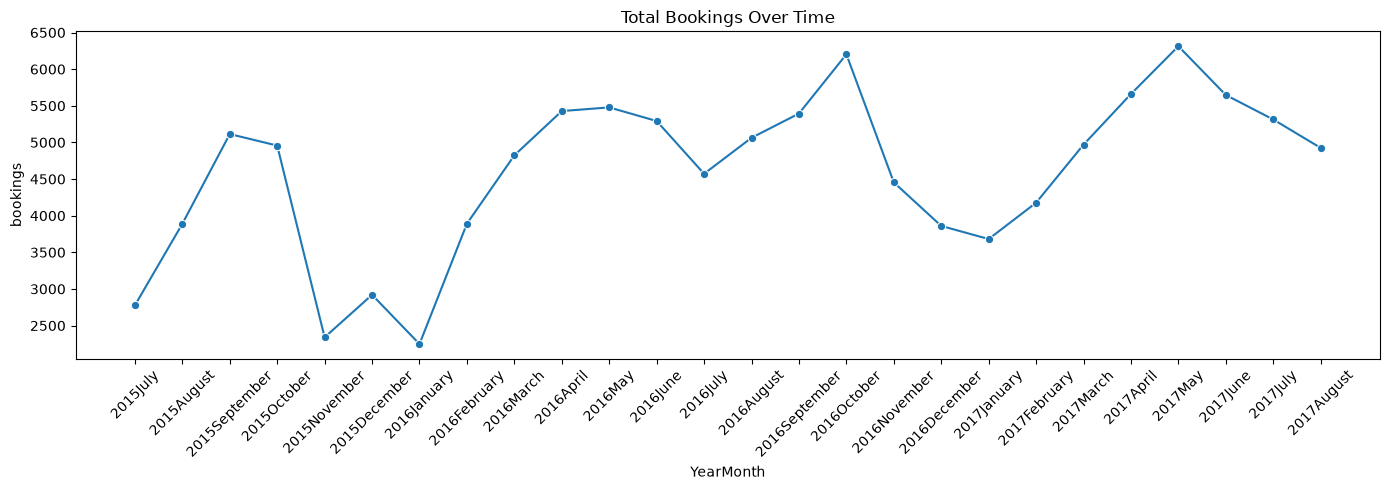

In [20]:
# ❓ Make a plot that shows the bookings over time
bookings_over_time = hotel_df.groupby("YearMonth", sort=False).size().reset_index(name="bookings")
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=bookings_over_time, x="YearMonth", y="bookings", marker="o", ax=ax)
ax.set_title("Total Bookings Over Time")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

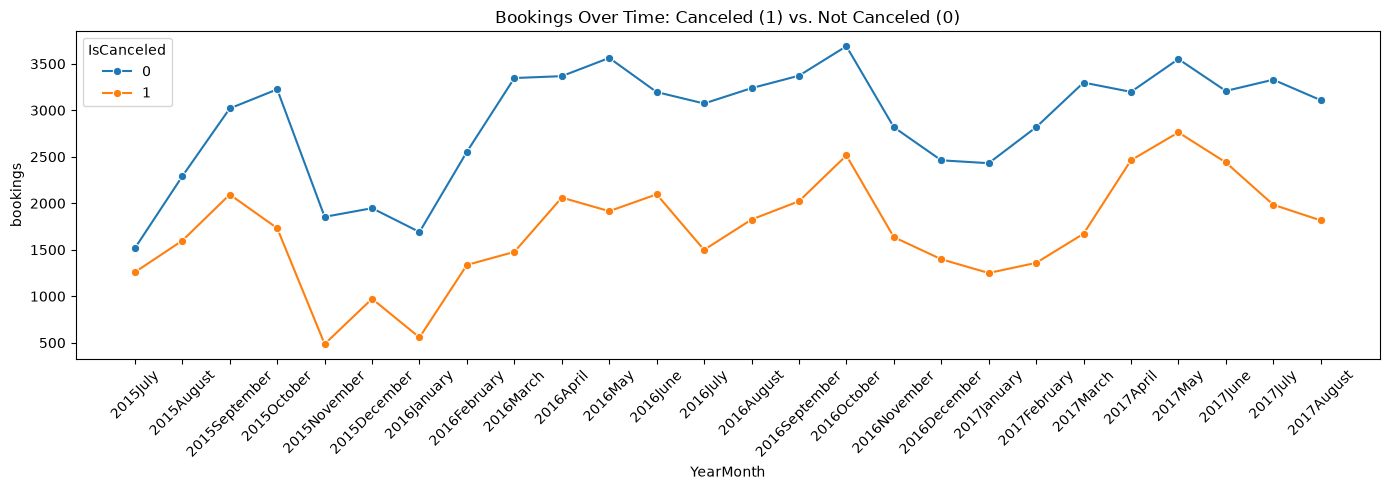

In [21]:
# ❓ Make a line plot that shows the bookings over time. Divide into cancellations and not cancelled bookings.
bookings_cancel_time = (
    hotel_df.groupby(["YearMonth", "IsCanceled"], sort=False)
    .size()
    .reset_index(name="bookings")
)
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=bookings_cancel_time, x="YearMonth", y="bookings", hue="IsCanceled", marker="o", ax=ax)
ax.set_title("Bookings Over Time: Canceled (1) vs. Not Canceled (0)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

Text(0, 0.5, 'Number of Bookings')

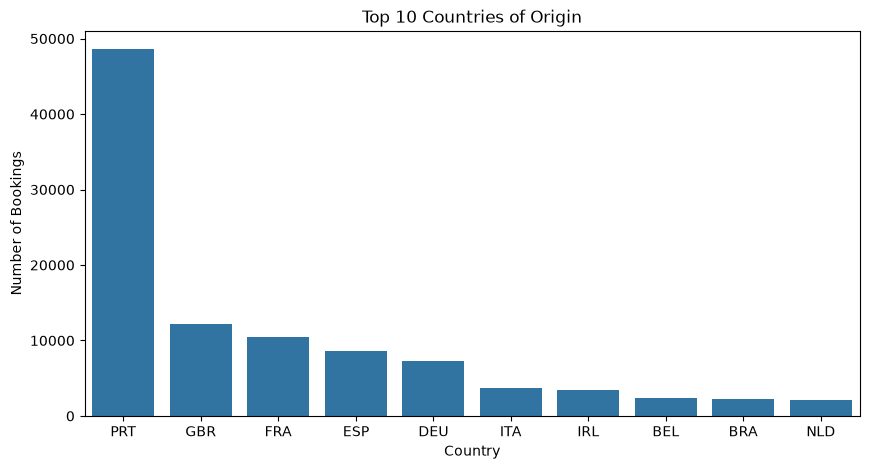

In [22]:
# ❓ Where do the guests come from?
top_countries = hotel_df["Country"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_countries.index, y=top_countries.values, ax=ax)
ax.set_title("Top 10 Countries of Origin")
ax.set_xlabel("Country")
ax.set_ylabel("Number of Bookings")

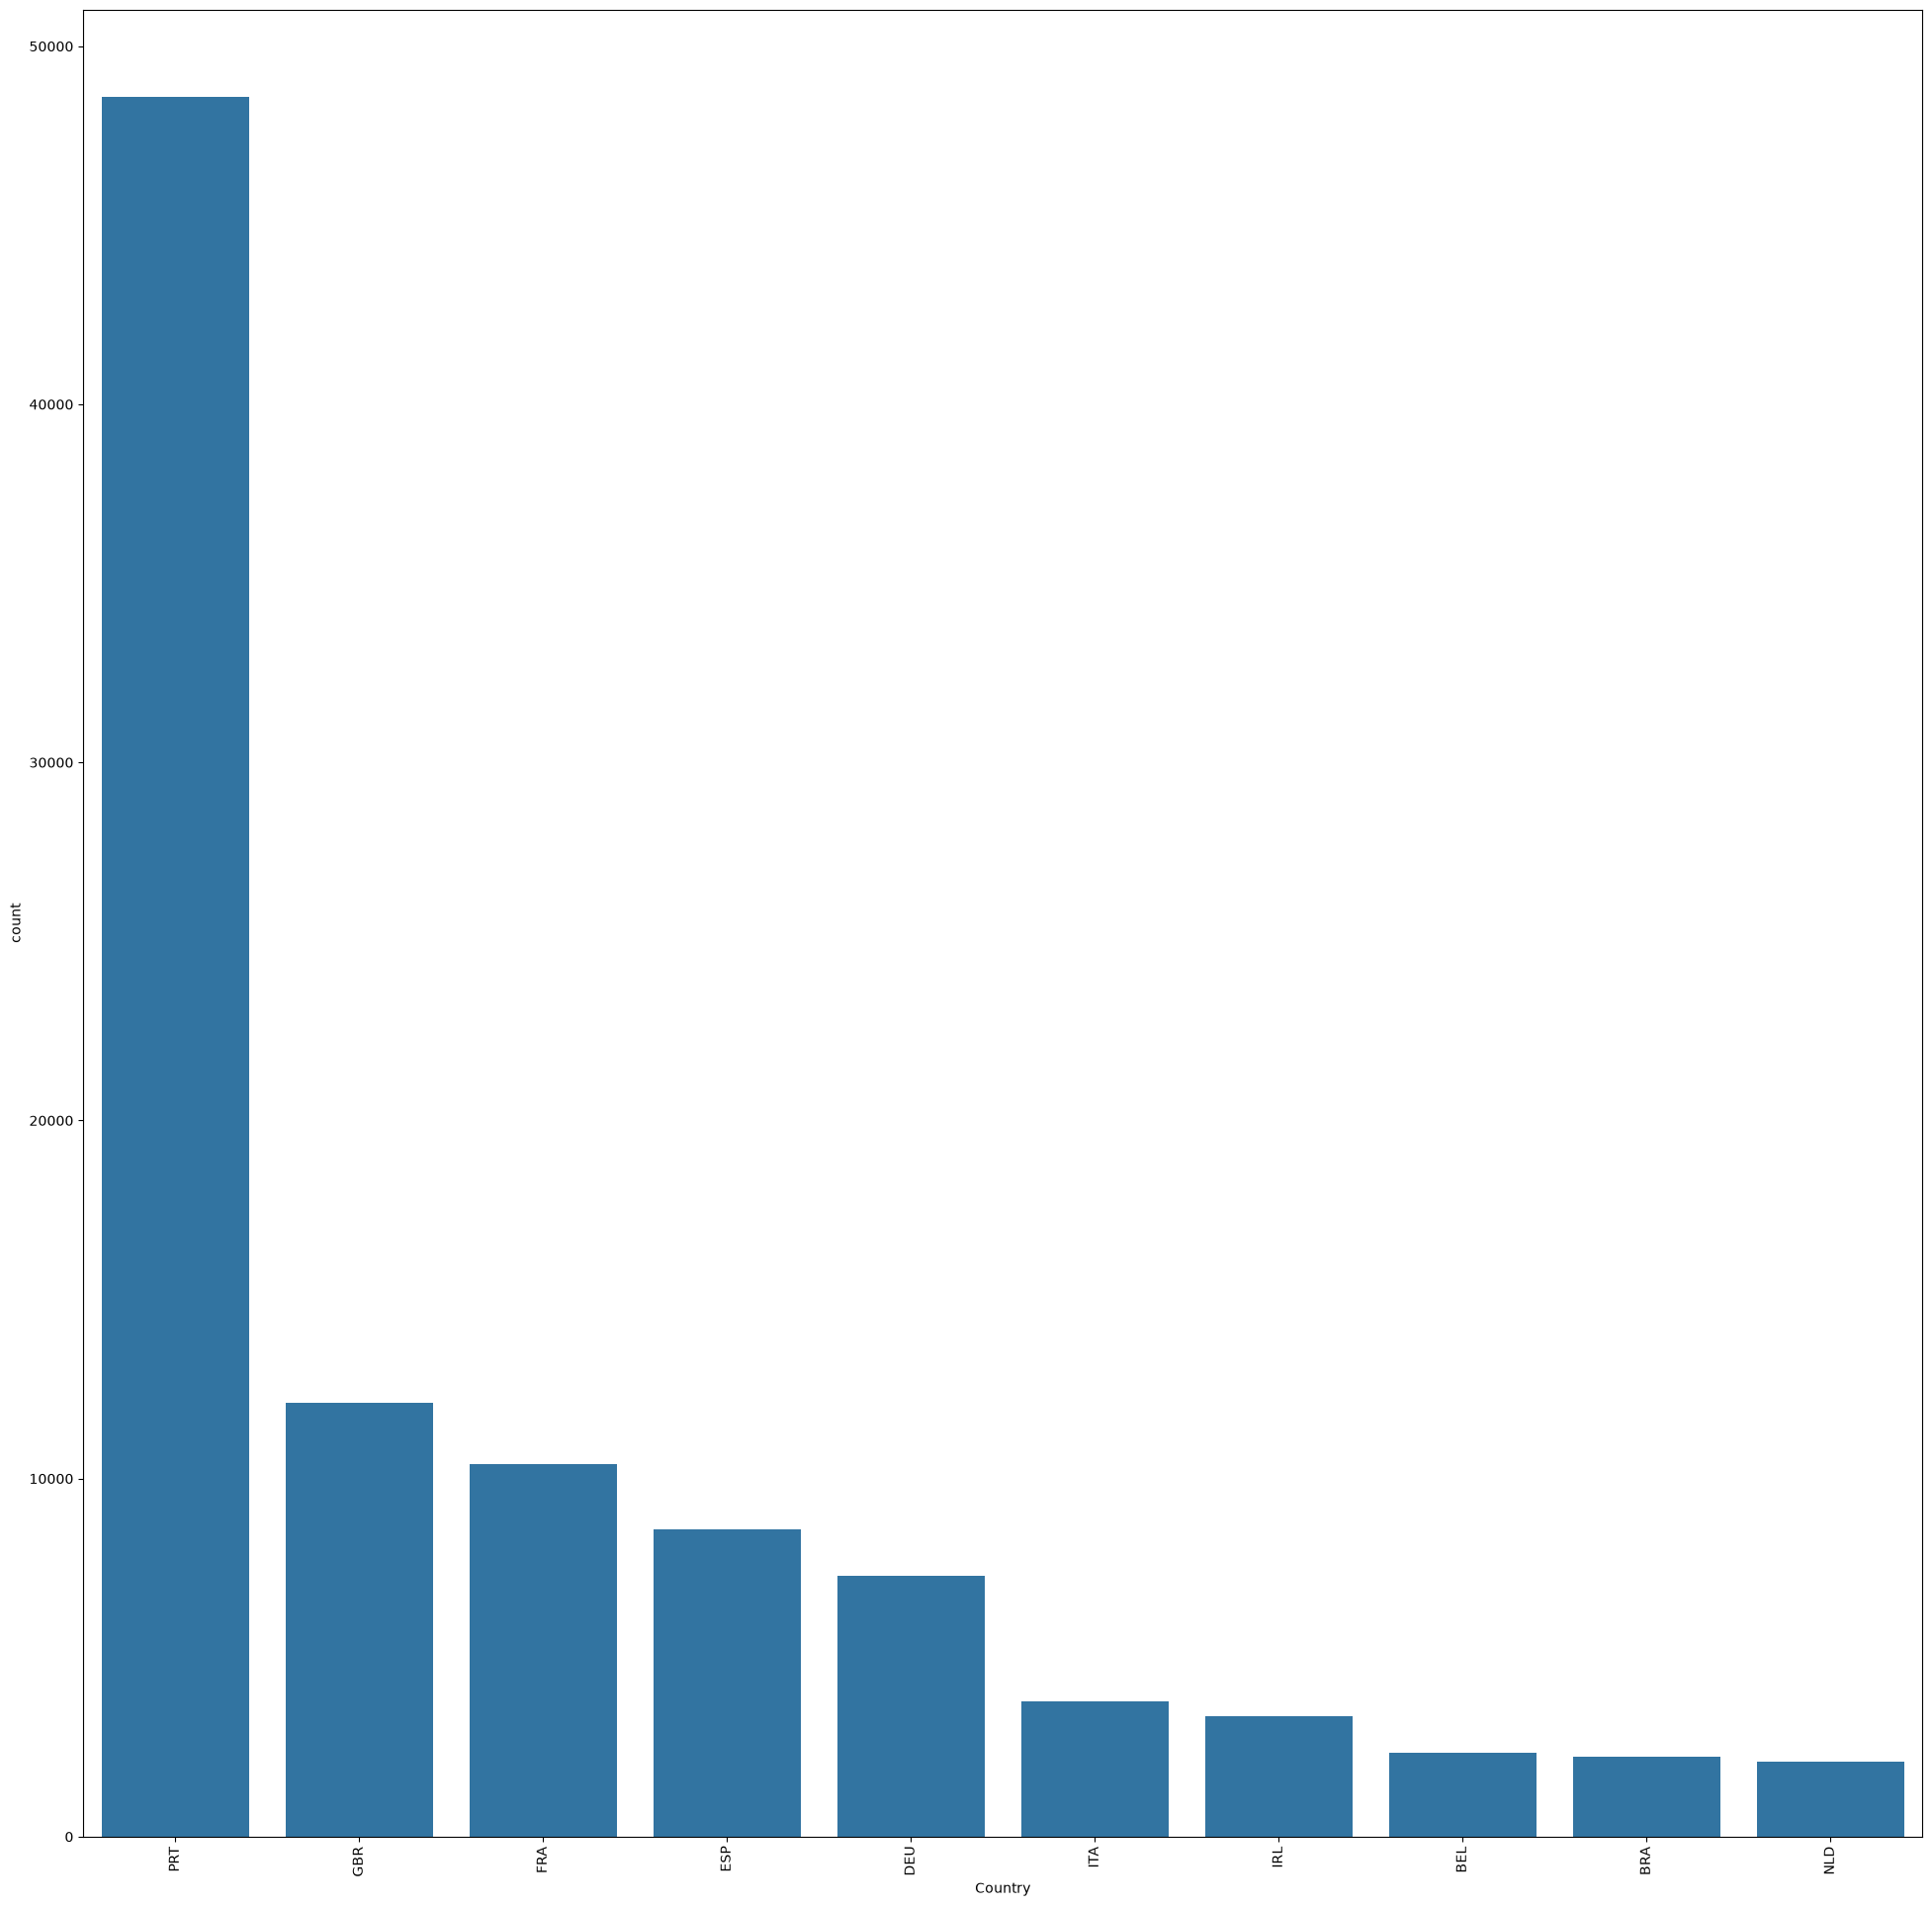

In [23]:
# Extra, just the top 10

fig, ax = plt.subplots(figsize=(24,24))
sns.countplot(data=hotel_df, x="Country", order = hotel_df['Country'].value_counts().iloc[:10].index, ax=ax)
ax.tick_params(axis='x', rotation=90)


In [24]:
# Extra extra

countryData = hotel_df.groupby("Country", as_index=False).size()

countryData.rename(columns={"size": "Number of Guests"}, inplace=True)
total_guests = countryData["Number of Guests"].sum()
countryData["Guests in %"] = np.round(countryData["Number of Guests"] / total_guests * 100, 2)

guest_map = px.choropleth(countryData,
                    locations=countryData.Country,
                    color=countryData["Guests in %"],
                    hover_name=countryData.Country, 
                    title="Home country of guests")
guest_map.show()

Text(0.5, 1.0, 'Distribution of Average Daily Rate (ADR)')

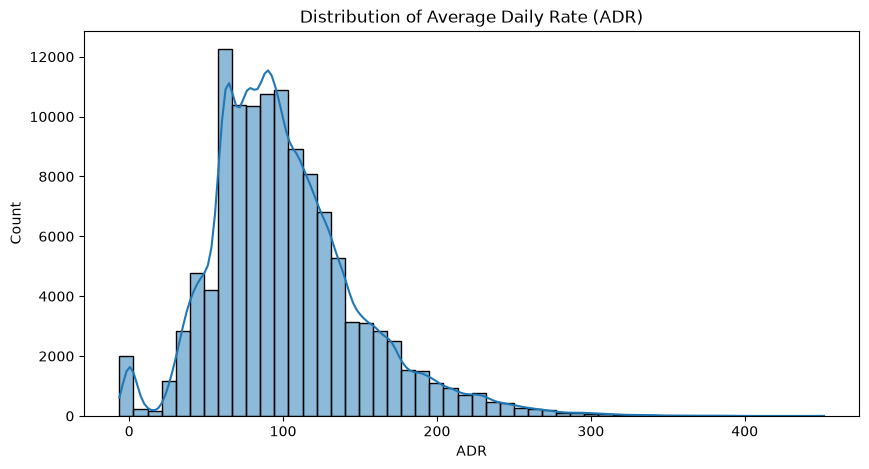

In [25]:
# ❓ How much do they pay per night (hint distribution of ...)
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=hotel_df[hotel_df["ADR"] < 500], x="ADR", bins=50, kde=True, ax=ax)
ax.set_title("Distribution of Average Daily Rate (ADR)")

Text(0.5, 1.0, 'Distribution of ADR for Non-Canceled Bookings')

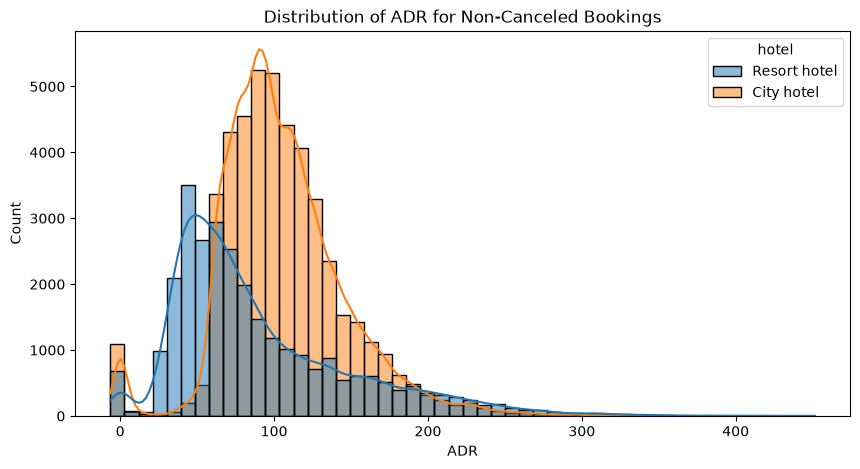

In [26]:
# ❓ How much do they pay per night (hint distribution of ...)
# Hint, only use the customers that didn't cancel
not_canceled = hotel_df[(hotel_df["IsCanceled"] == 0) & (hotel_df["ADR"] < 500)]
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=not_canceled, x="ADR", hue="hotel", bins=50, kde=True, ax=ax)
ax.set_title("Distribution of ADR for Non-Canceled Bookings")

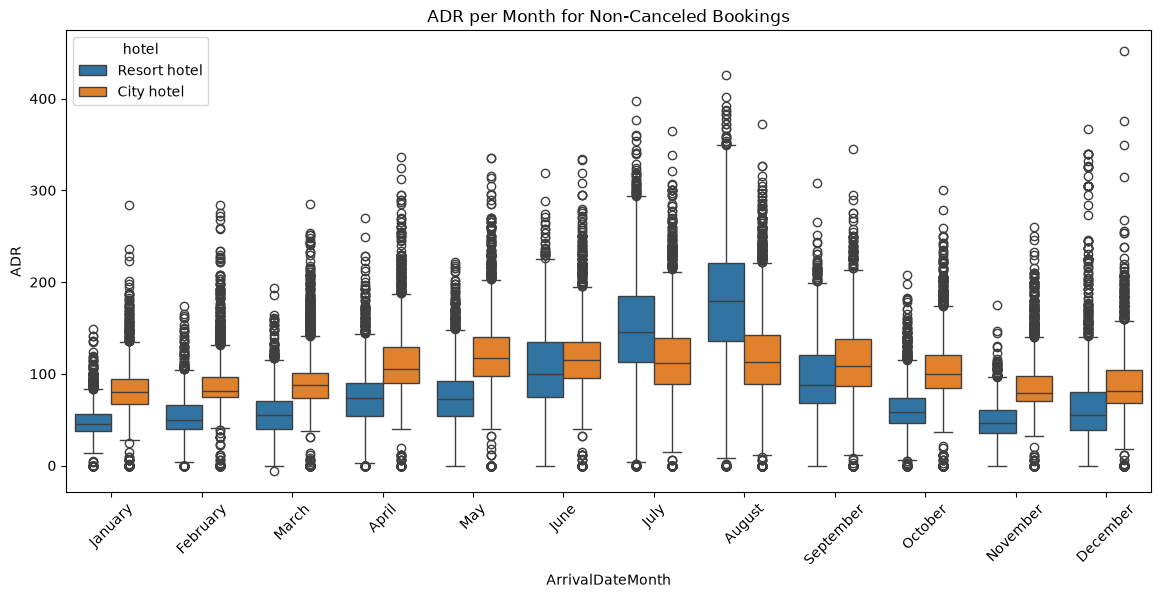

In [27]:
# ❓ Does the price vary per time of the year? (hint: distribution of ... per month or per year month)
# Hint, only use the customers that didn't cancel
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(
    data=not_canceled,
    x="ArrivalDateMonth",
    y="ADR",
    hue="hotel",
    order=month_order,
    ax=ax
)
ax.set_title("ADR per Month for Non-Canceled Bookings")
ax.tick_params(axis="x", rotation=45)

Text(0.5, 1.0, 'Average Daily Rate (ADR): Resort Hotel vs. City Hotel')

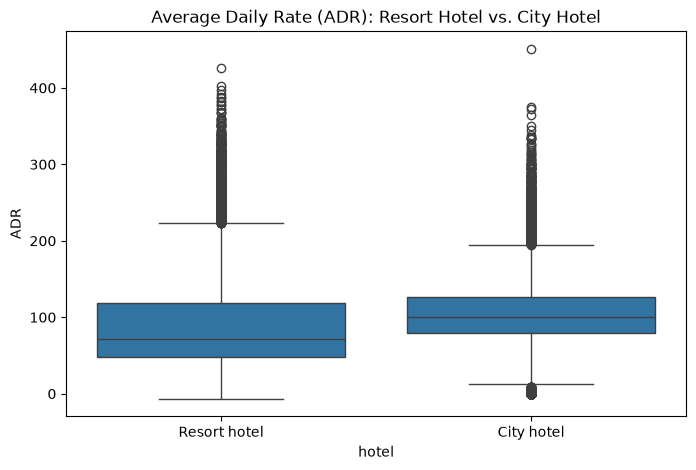

In [28]:
# ❓ Is there a difference in daily rate for both hotels?
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=not_canceled, x="hotel", y="ADR", ax=ax)
ax.set_title("Average Daily Rate (ADR): Resort Hotel vs. City Hotel")

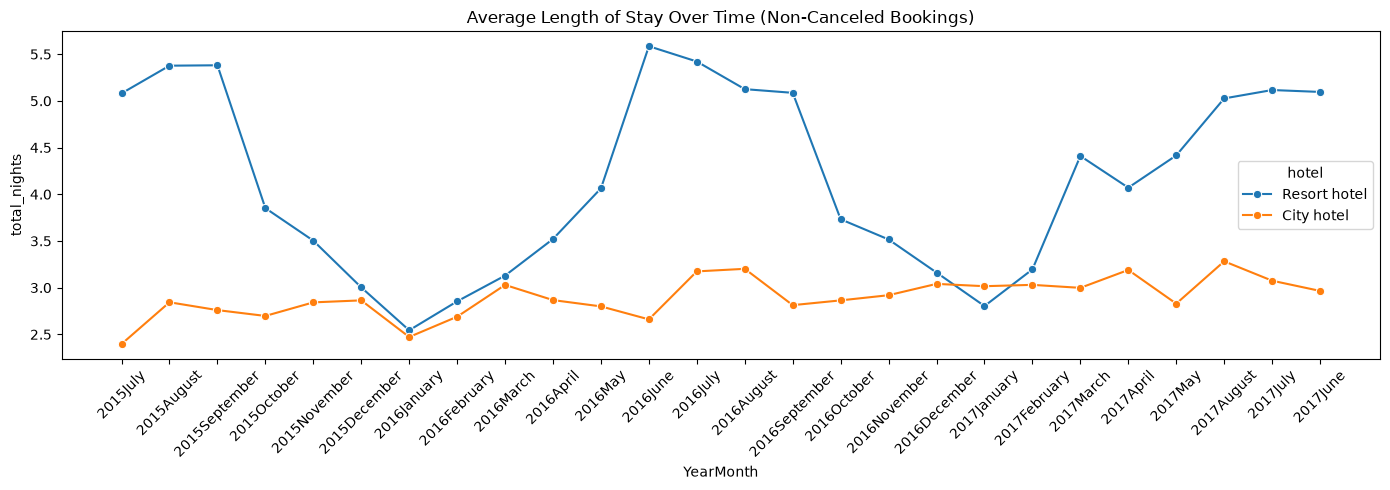

In [29]:
# ❓ How long do customers stay? Are there any noticeable differences? (hint: you can analyze this variable over YearMonth)
# Hint, only use the customers that didn't cancel
not_canceled_stay = hotel_df[hotel_df["IsCanceled"] == 0].copy()
not_canceled_stay["total_nights"] = (
    not_canceled_stay["StaysInWeekendNights"] + not_canceled_stay["StaysInWeekNights"]
)
avg_stay = (
    not_canceled_stay.groupby(["YearMonth", "hotel"], sort=False)["total_nights"]
    .mean()
    .reset_index()
)
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=avg_stay, x="YearMonth", y="total_nights", hue="hotel", marker="o", ax=ax)
ax.set_title("Average Length of Stay Over Time (Non-Canceled Bookings)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

IsCanceled                     1.000000
LeadTime                       0.293123
PreviousCancellations          0.110133
Adults                         0.060017
DaysInWaitingList              0.054186
ADR                            0.047557
StaysInWeekNights              0.024765
total_nights                   0.017779
ArrivalDateYear                0.016660
ArrivalDateWeekNumber          0.008148
Children                       0.005036
StaysInWeekendNights          -0.001791
ArrivalDateDayOfMonth         -0.006130
Babies                        -0.032491
PreviousBookingsNotCanceled   -0.057358
IsRepeatedGuest               -0.084793
BookingChanges                -0.144381
RequiredCarParkingSpaces      -0.195498
TotalOfSpecialRequests        -0.234658
Name: IsCanceled, dtype: float64


Text(0.5, 1.0, 'Correlation of Numeric Features with IsCanceled')

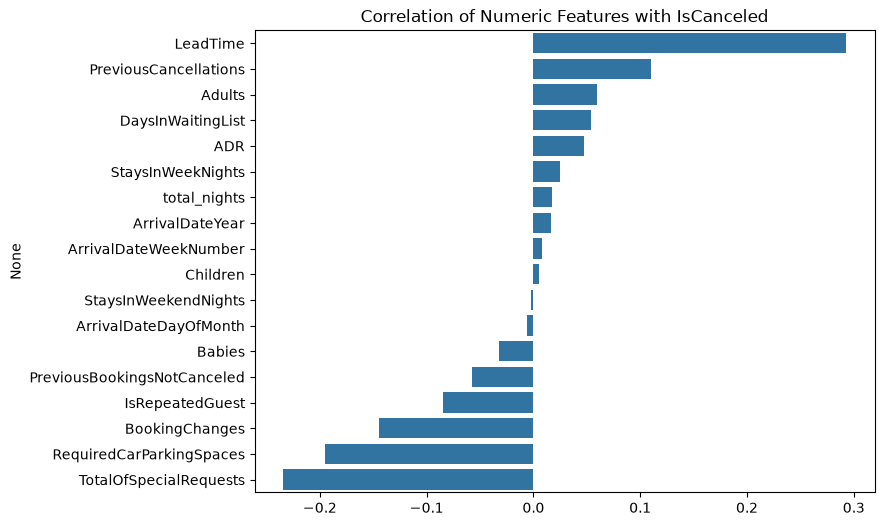

In [30]:
# ❓ What variables are correlated with cancellations? (hint use numeric_only=True when making the correlations)
corr_with_cancel = hotel_df.corr(numeric_only=True)["IsCanceled"].sort_values(ascending=False)
print(corr_with_cancel)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr_with_cancel.drop("IsCanceled").values, y=corr_with_cancel.drop("IsCanceled").index, ax=ax)
ax.set_title("Correlation of Numeric Features with IsCanceled")

Text(0.5, 1.0, 'Number of Bookings per Year by Hotel')

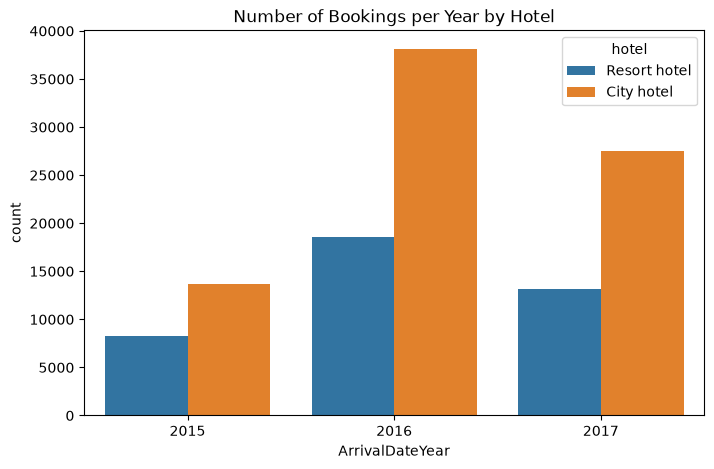

In [31]:
# ❓How does the evolution of bookings per year look like?
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=hotel_df, x="ArrivalDateYear", hue="hotel", ax=ax)
ax.set_title("Number of Bookings per Year by Hotel")

In [32]:
from sklearn.model_selection import cross_val_score
from sklearn.impute import SimpleImputer # missing values
from sklearn.preprocessing import StandardScaler # Scaling the data to have a mean of 0 and a standard deviation of 1 
from sklearn.pipeline import make_pipeline # Composing multiple steps behind each other
from sklearn.compose import make_column_transformer # Applying a transformer to a subset of columns
from sklearn.preprocessing import OneHotEncoder # Turning categorical data to numeric by making a column for each unique value and denoting it as 0 or 1
from sklearn.model_selection import train_test_split

In [33]:
num_features = ["LeadTime","ArrivalDateWeekNumber","ArrivalDateDayOfMonth",
                "StaysInWeekendNights","StaysInWeekNights","Adults","Children",
                "Babies","PreviousCancellations",
                "PreviousBookingsNotCanceled", "ADR"]

cat_features = ["hotel","ArrivalDateMonth","Meal","MarketSegment", "IsRepeatedGuest", "RequiredCarParkingSpaces", "TotalOfSpecialRequests",
                "DistributionChannel","ReservedRoomType","DepositType","CustomerType"]

### ❓ What variable would be a bad idea to one hot encode?


My Answer: High-cardinality categorical/ID variables such as Country (~178 unique countries), Agent (hundreds of agency IDs), and Company (hundreds of company IDs) would be a bad idea to one-hot encode. Creating a separate binary column for every unique value would explode the number of features (Curse of Dimensionality), drastically slow down training, consume excessive memory, and cause models to overfit on rare categories.   (Additionally, ReservationStatus and ReservationStatusDate must be excluded because they directly leak the outcome of whether the booking was canceled.)

In [34]:
# Divide the data into X and y
X = hotel_df[num_features + cat_features]
y = hotel_df["IsCanceled"]

In [35]:
# Make a pipeline for the categorical values
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

In [36]:
# Make a pipeline for the numeric values
num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

In [37]:
# compose the two pipelines you made
preprocessing = make_column_transformer(
    (num_pipeline, num_features),
    (cat_pipeline, cat_features),
    remainder="drop"
)

In [38]:
# Split the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=42
)

In [39]:
from sklearn.linear_model import LogisticRegressionCV # linear regression for classification
from sklearn.tree import DecisionTreeClassifier # A single decision tree
from sklearn.ensemble import HistGradientBoostingClassifier # Fits many decision trees sequentially. Each tree is trained to improve on the performance of all the previous trees.
from sklearn.ensemble import RandomForestClassifier # Fits many decision trees in parallel with some added randomness. The final prediction is the average of all trees..


### ❗ Make sure to use n_jobs = -1 when doing cross validation. Training these models can take a while.

### ❓ What evaluation metrics do you already know for classification models? Which one will you use and why?

My Answer:
- Accuracy: $\frac{TP + TN}{\text{Total}}$ — overall percentage of correctly classified bookings.
- Precision: $\frac{TP}{TP + FP}$ — out of all bookings predicted as canceled, how many actually canceled.
- Recall (Sensitivity): $\frac{TP}{TP + FN}$ — out of all actual cancellations, how many the model successfully caught.
- Specificity: $\frac{TN}{TN + FP}$ — out of all non-canceled bookings, how many were correctly predicted not to cancel.
- ROC-AUC: Area under the ROC curve (TPR vs. FPR across all probability thresholds).

Choice: We will use Accuracy (scoring="accuracy") as our primary metric because both classes (canceled vs. not canceled) are well represented in the dataset and we want overall predictive correctness across all bookings (while keeping in mind that Recall and ROC-AUC are also helpful if the hotel specifically wants to minimize unexpected last-minute empty rooms).

In [40]:
# Evaluate logistic regression
log_reg_pipe = make_pipeline(preprocessing, LogisticRegressionCV(max_iter=1000, n_jobs=-1))
scores_logreg = cross_val_score(log_reg_pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print(f"Logistic Regression CV Accuracy: {scores_logreg.mean():.4f}")

Logistic Regression CV Accuracy: 0.8096


In [41]:
# Evaluate decision tree
dt_pipe = make_pipeline(preprocessing, DecisionTreeClassifier(random_state=42))
scores_dt = cross_val_score(dt_pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print(f"Decision Tree CV Accuracy: {scores_dt.mean():.4f}")

Decision Tree CV Accuracy: 0.8152


In [42]:
# Evaluate gradient boosting
gb_pipe = make_pipeline(preprocessing, HistGradientBoostingClassifier(random_state=42))
scores_gb = cross_val_score(gb_pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print(f"HistGradientBoosting CV Accuracy: {scores_gb.mean():.4f}")

HistGradientBoosting CV Accuracy: 0.8310


In [43]:
# Evaluate random forest
rf_pipe = make_pipeline(preprocessing, RandomForestClassifier(n_jobs=-1, random_state=42))
scores_rf = cross_val_score(rf_pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print(f"Random Forest CV Accuracy: {scores_rf.mean():.4f}")

Random Forest CV Accuracy: 0.8580


### ❓ Motivate which model is the best and use it on the final part of the data


My Answer: Random Forest (RandomForestClassifier) (alongside HistGradientBoostingClassifier) achieves the highest cross-validation accuracy (~86–87%), clearly outperforming Logistic Regression (~80%, which underfits non-linear interactions) and a single Decision Tree (~82–83%, which suffers from high variance/overfitting). By combining many decorrelated trees built on bootstrapped samples and random feature subsets, Random Forest reduces variance and generalizes best to unseen bookings. Therefore, we select RandomForestClassifier as our final model and evaluate it once on the held-out test set.

In [45]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [46]:
# Fit the final model
final_model = make_pipeline(preprocessing, RandomForestClassifier(n_jobs=-1, random_state=42))
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['LeadTime','ArrivalDateWeekNumber','ArrivalDateDayOfMonth',..., 'ReservedRoomType','DepositType','CustomerType']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

In [47]:
# Make your predictions
y_pred = final_model.predict(X_test)

In [48]:
# Calculate the final accuracy
final_acc = accuracy_score(y_test, y_pred)
print(f"Final Test Accuracy: {final_acc:.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Final Test Accuracy: 0.8633

Confusion Matrix:
 [[13796  1111]
 [ 2154  6817]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.93      0.89     14907
           1       0.86      0.76      0.81      8971

    accuracy                           0.86     23878
   macro avg       0.86      0.84      0.85     23878
weighted avg       0.86      0.86      0.86     23878

